# Práctica: PIB per cápita

**Materia:** Tópicos de Big Data
**Fuente:** Our World in Data (OWID) / Banco Mundial, indicador *GDP per capita*

**Objetivo:** extraer, limpiar y analizar la serie histórica del PIB per cápita
(dólares internacionales constantes, PPA), con foco en México y comparación
internacional.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

OPCIONES_OWID = {"User-Agent": "Our World In Data data fetch/1.0"}

## 1. Extracción del dataset

In [2]:
url_pib = (
    "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv"
    "?v=1&csvType=full&useColumnShortNames=true"
)

pib = pd.read_csv(url_pib, storage_options=OPCIONES_OWID)
pib.shape

(7445, 5)

## 2. Exploración inicial

In [3]:
pib.head()

,entity,code,year,ny_gdp_pcap_pp_kd,owid_region
0,Afghanistan,AFG,2000,1617.8264,Asia
1,Afghanistan,AFG,2001,1454.1108,Asia
2,Afghanistan,AFG,2002,1774.3087,Asia
3,Afghanistan,AFG,2003,1815.9282,Asia
4,Afghanistan,AFG,2004,1776.9182,Asia


In [4]:
pib.columns.tolist()

['entity', 'code', 'year', 'ny_gdp_pcap_pp_kd', 'owid_region']

In [5]:
pib.isnull().sum()

entity                 0
code                   0
year                   0
ny_gdp_pcap_pp_kd      0
owid_region          468
dtype: int64

## 3. Renombrar columnas

In [6]:
col_pib = [c for c in pib.columns if c.startswith("ny_gdp_pcap")][0]

pib = pib.rename(columns={
    "entity": "pais",
    "code": "codigo",
    "year": "anio",
    col_pib: "pib_per_capita",
    "owid_region": "region",
})

pib.head(3)

,pais,codigo,anio,pib_per_capita,region
0,Afghanistan,AFG,2000,1617.8264,Asia
1,Afghanistan,AFG,2001,1454.1108,Asia
2,Afghanistan,AFG,2002,1774.3087,Asia


## 4. México: evolución del PIB per cápita (2000–2023)

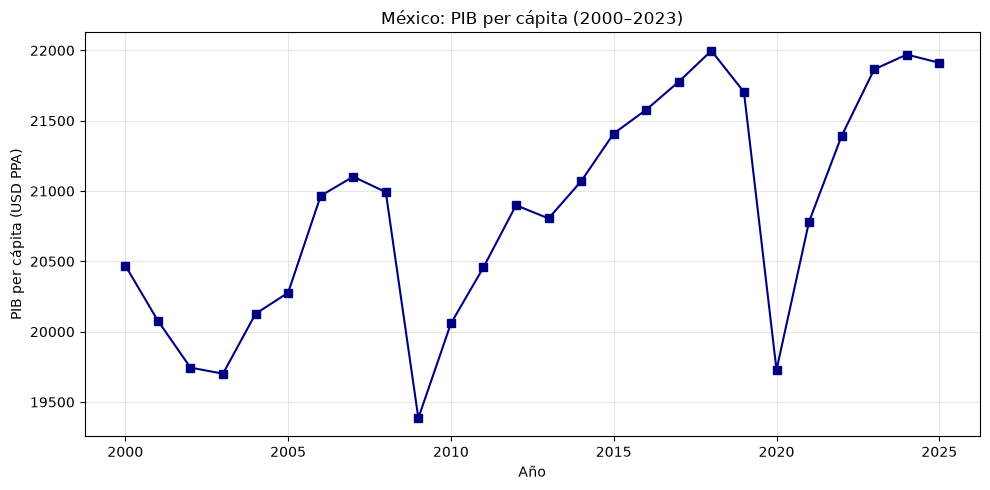

In [7]:
mexico_pib = pib[(pib["pais"] == "Mexico") & (pib["anio"] >= 2000)].sort_values("anio")

plt.figure(figsize=(10, 5))
plt.plot(mexico_pib["anio"], mexico_pib["pib_per_capita"], marker="s", color="navy")
plt.title("México: PIB per cápita (2000–2023)")
plt.xlabel("Año")
plt.ylabel("PIB per cápita (USD PPA)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Comparación internacional

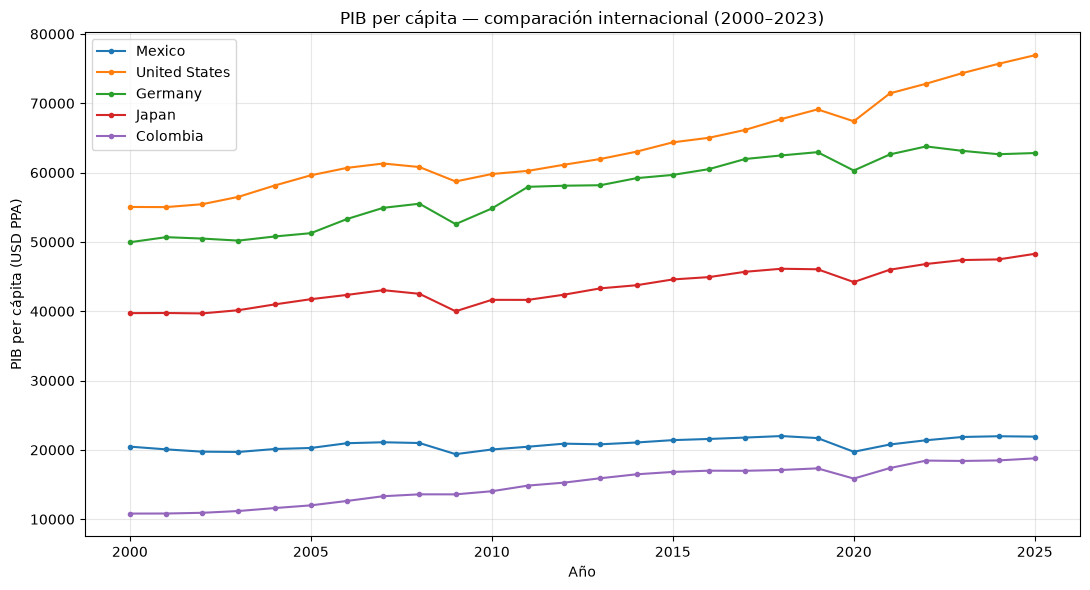

In [8]:
paises = ["Mexico", "United States", "Germany", "Japan", "Colombia"]
comparacion = pib[(pib["pais"].isin(paises)) & (pib["anio"] >= 2000)]

plt.figure(figsize=(11, 6))
for pais in paises:
    datos_pais = comparacion[comparacion["pais"] == pais]
    plt.plot(datos_pais["anio"], datos_pais["pib_per_capita"], marker=".", label=pais)

plt.title("PIB per cápita — comparación internacional (2000–2023)")
plt.xlabel("Año")
plt.ylabel("PIB per cápita (USD PPA)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Top 10 países con mayor PIB per cápita (2023)

In [9]:
top_2023 = (
    pib[(pib["anio"] == 2023) & (pib["codigo"].notna())]
    .sort_values("pib_per_capita", ascending=False)
    .head(10)
)
top_2023[["pais", "codigo", "pib_per_capita", "region"]]

,pais,codigo,pib_per_capita,region
6023,Singapore,SGP,130296.84,Asia
3960,Luxembourg,LUX,130048.92,Europe
3187,Ireland,IRL,117659.73,Europe
5497,Qatar,QAT,116159.14,Asia
3996,Macao,MAC,104815.20,Asia
740,Bermuda,BMU,102268.92,North America
5033,Norway,NOR,94364.96,Europe
6543,Switzerland,CHE,85383.36,Europe
1227,Cayman Islands,CYM,79580.89,North America
955,Brunei,BRN,76616.70,Asia
